# ACME Inc. — Performance & Talent Insights

**Audience:** HR leadership (business) and the data platform team (technical).
**Source:** Gold layer of the `talent-pipeline` (Bronze → Silver → Gold), read from the data lake (S3 / LocalStack).

Each section answers one business question: the question, the evidence (chart + table), and a plain-English **"So what?"**.

| # | Business question | Gold table(s) |
|---|---|---|
| Q1 | What are the performance ratings and review history for each employee? | `gold_employee_performance`, `gold_review_history` |
| Q2 | Which employees have critical skill gaps in key competencies? | `gold_critical_skill_gaps` |
| Q3 | Who are the high-potential employees ready for promotion? | `gold_promotion_candidates` |
| Q4 | What training and development activities have been completed by each employee? | `gold_employee_learning`, `gold_course_completions` |
| Q5 | Which employees are at risk of attrition based on performance trends? | `gold_attrition_risk` |
| Q6 | How does employee performance correlate with team and project outcomes? | `gold_team_outcomes` |
| Q7 | What is the distribution of skills across the organization? | `gold_skill_distribution` |

> **How to run:** run `python job.py` first, then *Kernel → Restart & Run All*. The notebook reads the same environment variables as the pipeline (`DATA_LAKE_URI`, `IS_LOCAL`, `AWS_ENDPOINT_URL`, …), so nothing is hard-coded. Every Gold table is also in PostgreSQL (schema `gold`) for SQL users — see `sql/business_questions.sql`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

sys.path.insert(0, str(Path.cwd().parent))  # make the pipeline package importable from notebooks/
from pipeline.config import load_settings
from pipeline.storage import open_lake
from pipeline.gold import BUSINESS_QUESTIONS, RULES

settings = load_settings()
lake = open_lake(settings)
gold = {name: lake.read_parquet(f"gold/{name}/") for name in BUSINESS_QUESTIONS}

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13})
BLUE, RED, GREY, GREEN, ORANGE = "#2E6FBA", "#C8453B", "#9AA0A6", "#3A9D5D", "#E08E2B"

print(f"Data lake: {lake.uri}")
for name, df in gold.items():
    print(f"  {name:<28} {len(df):>6,} rows")

/usr/lib/python3/dist-packages/pytz/__init__.py:31: SyntaxWarning: invalid escape sequence '\s'
  match = re.match("^#\s*version\s*([0-9a-z]*)\s*$", line)


Data lake: s3://talent-lake-c6821386
  gold_employee_performance     2,000 rows
  gold_review_history           4,000 rows
  gold_critical_skill_gaps        325 rows
  gold_promotion_candidates       357 rows
  gold_employee_learning        2,000 rows
  gold_course_completions       3,421 rows
  gold_attrition_risk             260 rows
  gold_team_outcomes              100 rows
  gold_skill_distribution         400 rows
  gold_employee_360             2,000 rows


## 0. Can we trust the data? (pipeline health)

Before answering business questions we check the latest run: rows read, rows quarantined (and why), and whether every reconciliation check passed. Bad rows are **isolated, not silently dropped** — they sit in `quarantine/<table>/run_date=…/` with the reason attached.

In [2]:
runs = sorted(k for k in lake.list_keys("_runs/") if k.endswith(".json"))
manifest = lake.read_json(runs[-1])
print(f"Latest run: {manifest['run_id']}  status={manifest['status']}  duration={manifest['duration_s']}s")

rows = []
for step in manifest["steps"]:
    if step["name"].startswith("silver."):
        m = step["metrics"]
        rows.append({"table": step["name"].removeprefix("silver."), "rows_in": m["rows_in"], "valid": m["rows_valid"],
                     "quarantined": m.get("quarantine_rows", m["rows_rejected"]),
                     "duplicates_dropped": m["exact_duplicates_dropped"]})
checks = pd.DataFrame(manifest["reconciliation"])
print(f"Reconciliation: {checks['passed'].sum()}/{len(checks)} checks passed")
pd.DataFrame(rows).set_index("table")

Latest run: 20261015T071226Z-059ff5af  status=success  duration=22.421s
Reconciliation: 30/30 checks passed


,rows_in,valid,quarantined,duplicates_dropped
table,,,,
teams,100,100,0,0
competencies,40,40,0,0
employees,2000,2000,0,0
projects,33,33,0,0
performance_reviews,4000,4000,0,0
competency_assessments,4000,4000,0,0
talent_review,2000,2000,0,0
learning_activity,29855,29574,143,151


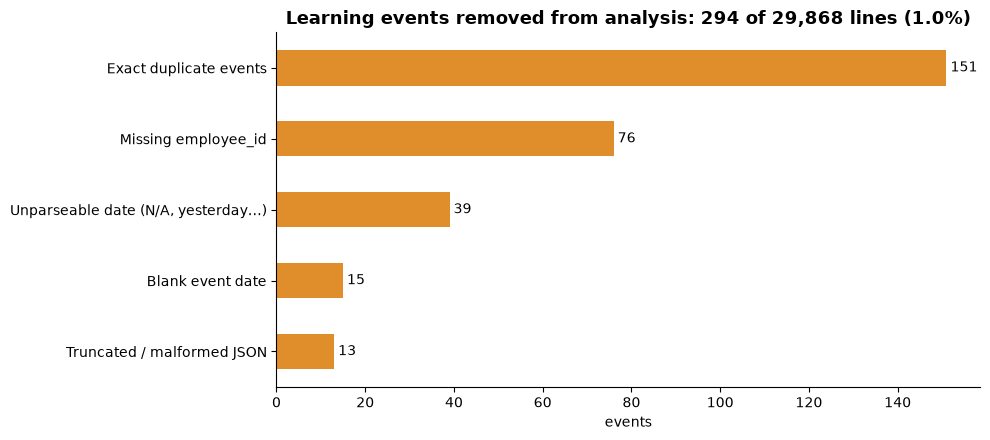

Schema drift handled: 39 records used a legacy 'notes' field and were mapped to 'text'.


In [3]:
la = next(s for s in manifest["steps"] if s["name"] == "silver.learning_activity")["metrics"]
reasons = {"Truncated / malformed JSON": la["lines_malformed"], "Exact duplicate events": la["exact_duplicates_dropped"]}
labels = {"missing_required:employee_id": "Missing employee_id",
          "invalid_type:event_date": "Unparseable date (N/A, yesterday…)",
          "missing_required:event_date": "Blank event date"}
for key, n in la["reject_reasons"].items():
    reasons[labels.get(key, key)] = n
s = pd.Series(reasons).sort_values()
ax = s.plot.barh(color=ORANGE)
ax.set_title(f"Learning events removed from analysis: {s.sum():,} of {la['lines_total']:,} lines ({s.sum()/la['lines_total']:.1%})")
ax.set_xlabel("events")
for i, v in enumerate(s):
    ax.text(v, i, f" {v}", va="center")
plt.tight_layout(); plt.show()
print(f"Schema drift handled: {la['schema_drift_notes_to_text']} records used a legacy 'notes' field and were mapped to 'text'.")

**So what?** The seven HR tables are clean. The learning-activity feed is not: about 1% of events are broken, duplicated or unattributable. The pipeline catches all of them, keeps them for troubleshooting, and every row is accounted for (Bronze = Silver + quarantine + duplicates). The answers below are based on trusted data.

## Q1. What are the performance ratings and review history for each employee?

`gold_employee_performance` has **one row per employee** with every review period as its own column, the latest rating, the change, and a trend label. `gold_review_history` has **one row per review** for drill-down.

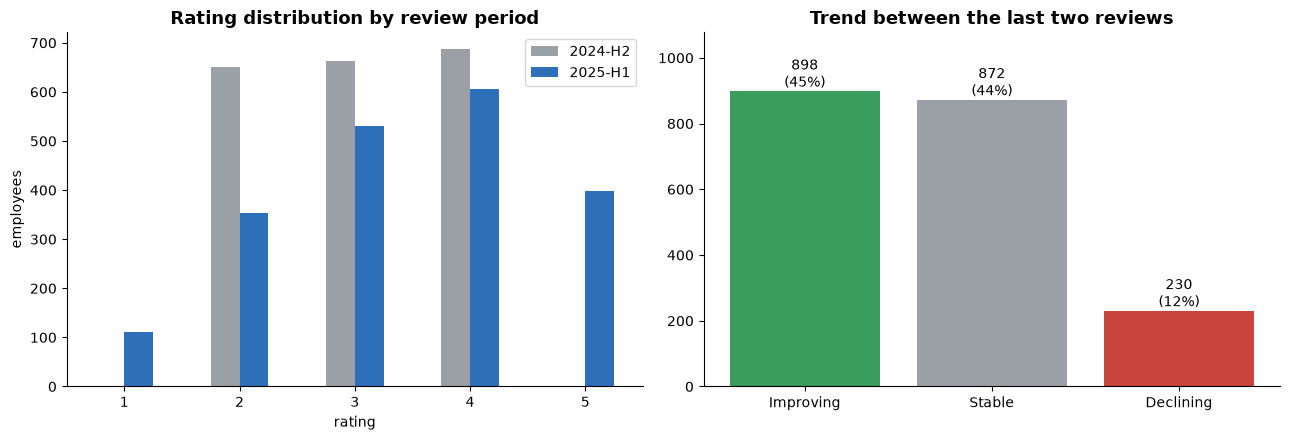

Average rating by period: {'rating_2024_h2': 3.02, 'rating_2025_h1': 3.41}


In [4]:
perf = gold["gold_employee_performance"]
period_cols = sorted(c for c in perf.columns if c[:7] == "rating_" and c[7:11].isdigit())
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
dist = pd.DataFrame({c.removeprefix("rating_").replace("_", "-").upper(): perf[c].value_counts().reindex(range(1, 6), fill_value=0)
                     for c in period_cols})
dist.plot.bar(ax=a1, color=[GREY, BLUE], rot=0)
a1.set_title("Rating distribution by review period"); a1.set_xlabel("rating"); a1.set_ylabel("employees")
trend = perf["performance_trend"].value_counts().reindex(["Improving", "Stable", "Declining"])
a2.bar(trend.index, trend.values, color=[GREEN, GREY, RED])
a2.set_title("Trend between the last two reviews")
for x, v in enumerate(trend.values):
    a2.text(x, v, f"{v:,}\n({v/len(perf):.0%})", ha="center", va="bottom")
a2.set_ylim(0, trend.max() * 1.2)
plt.tight_layout(); plt.show()
print("Average rating by period:", {c: round(float(perf[c].mean()), 2) for c in period_cols})

In [5]:
# One row per employee (first 10 shown) — filter this table for any person, team or department
perf[["employee_id", "full_name", "department", "job_level"] + period_cols +
     ["rating_change", "avg_rating", "performance_trend", "latest_manager_comment"]].head(10)

,employee_id,full_name,department,job_level,rating_2024_h2,rating_2025_h1,rating_change,avg_rating,performance_trend,latest_manager_comment
0,1,Heather Davis,Sales,Director,3,4,1,3.5,Improving,Delivered on commitments with no major concerns.
1,2,Kristie Heath,Sales,Director,4,5,1,4.5,Improving,"Solid, consistent contributor this cycle."
2,3,Brandon Scott,Sales,Senior Manager,4,5,1,4.5,Improving,"Solid, consistent contributor this cycle."
3,4,Gregory Williams,Sales,IC3,4,4,0,4.0,Stable,"Solid, consistent contributor this cycle."
4,5,Linda Murray,Sales,IC1,2,3,1,2.5,Improving,Strong upward trend across all review dimensions.
5,6,Claudia Cole,Sales,Manager,3,4,1,3.5,Improving,Strong upward trend across all review dimensions.
6,7,April Harrington,Sales,IC3,2,2,0,2.0,Stable,Delivered on commitments with no major concerns.
7,8,Sherry Coleman,Sales,IC2,3,2,-1,2.5,Declining,Missed several key deliverables this cycle; needs support.
8,9,Kyle Brown,Sales,Senior Manager,2,2,0,2.0,Stable,Met expectations across all core responsibilities.
9,10,Tracie Gomez,Sales,IC1,3,5,2,4.0,Improving,Consistently exceeded goals this cycle; ready for more scope.


In [6]:
# Full review history for one employee (change EMPLOYEE_ID to look anyone up)
EMPLOYEE_ID = int(perf.loc[perf["performance_trend"] == "Declining", "employee_id"].iloc[0])
gold["gold_review_history"].query("employee_id == @EMPLOYEE_ID")

,review_id,employee_id,full_name,department,team_name,review_period,review_sequence,rating,change_vs_previous,manager_comment,submitted_date
14,15,8,Sherry Coleman,Sales,Team LightYellow-1,2024-H2,1,3,<NA>,"Solid, consistent contributor this cycle.",2025-08-23
15,16,8,Sherry Coleman,Sales,Team LightYellow-1,2025-H1,2,2,-1,Missed several key deliverables this cycle; needs support.,2026-02-18


**So what?** Every employee has two reviews (2024-H2 and 2025-H1). Ratings shifted upward overall (average 3.02 → 3.41), and most people improved or stayed stable, but **230 employees (12%) declined** — that group feeds directly into the attrition analysis in Q5. HR can look up any individual's full history with the cell above.

*Data observation:* the 2024-H2 cycle only used ratings 2–4, while 2025-H1 used the full 1–5 scale. Part of the apparent improvement may be a change in how the scale was used, not only in performance — worth confirming with HR before reading too much into the trend.

## Q2. Which employees have critical skill gaps in key competencies?

**Definitions** (configurable in `pipeline/gold.py → RULES`):
* `skill_gap = required_level − proficiency_level`
* **Critical gap** = 2 or more levels below what the role requires
* **Key competency** = the role requires level 4 or higher

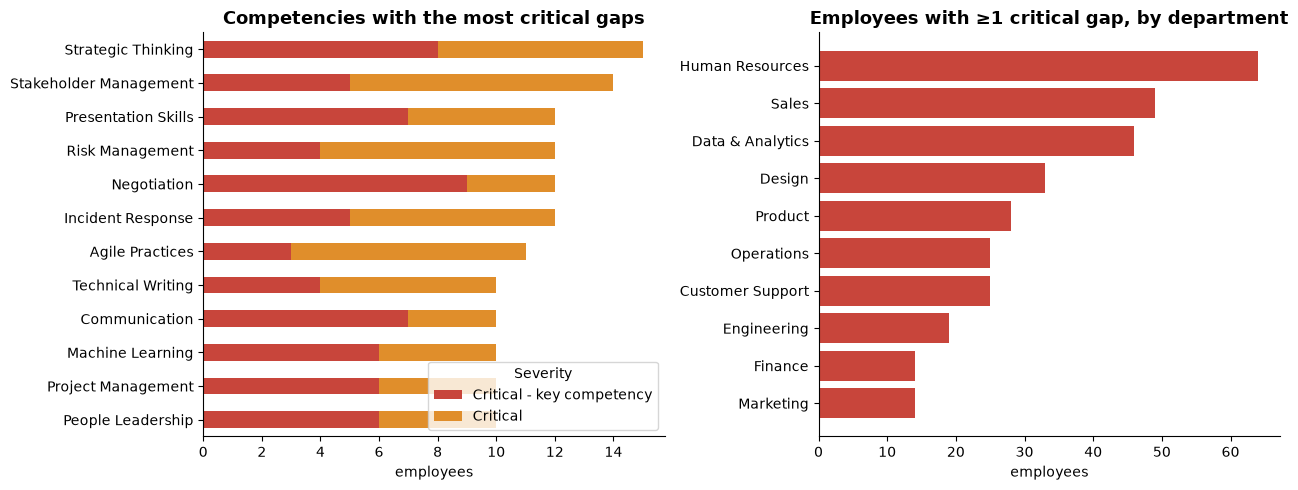

317 employees have 325 critical gaps; 177 are in key competencies (required level 4+).


In [7]:
cg = gold["gold_critical_skill_gaps"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
by_comp = cg.groupby(["competency_name", "severity"]).size().unstack(fill_value=0)
by_comp = by_comp.loc[by_comp.sum(axis=1).sort_values().index].tail(12)
by_comp[["Critical - key competency", "Critical"]].plot.barh(stacked=True, ax=a1, color=[RED, ORANGE])
a1.set_title("Competencies with the most critical gaps"); a1.set_xlabel("employees"); a1.set_ylabel("")
a1.legend(title="Severity", loc="lower right")
by_dept = cg.groupby("department")["employee_id"].nunique().sort_values()
a2.barh(by_dept.index, by_dept.values, color=RED)
a2.set_title("Employees with ≥1 critical gap, by department"); a2.set_xlabel("employees")
plt.tight_layout(); plt.show()
print(f"{cg['employee_id'].nunique()} employees have {len(cg)} critical gaps; "
      f"{(cg['severity'] == 'Critical - key competency').sum()} are in key competencies (required level 4+).")

In [8]:
# Priority list: critical gaps in key competencies, worst first
cg[cg["is_key_competency"]][["full_name", "department", "job_level", "competency_name", "category",
                              "required_level", "proficiency_level", "skill_gap", "latest_rating"]].head(15)

,full_name,department,job_level,competency_name,category,required_level,proficiency_level,skill_gap,latest_rating
0,Kristie Heath,Sales,Director,Strategic Thinking,Leadership,4,2,2,5
1,Douglas Salinas,Design,Director,Data Privacy,Domain,4,2,2,2
2,Lindsey Harris,Design,IC1,People Leadership,Leadership,4,2,2,3
3,Kelly Smith,Sales,Senior IC,Agile Practices,Domain,4,2,2,3
4,Christine Roberts,Sales,Senior Manager,Decision Making,Leadership,4,2,2,3
5,Cody Scott,Sales,IC3,Strategic Thinking,Leadership,4,2,2,5
6,Amanda Jackson,Customer Support,Senior Manager,Technical Writing,Domain,4,2,2,3
7,Ryan Baker,Finance,Director,Project Management,Domain,4,2,2,4
8,Lisa Smith,Product,IC2,Time Management,Domain,4,2,2,3
9,Sarah Young,Product,IC3,Stakeholder Management,Domain,4,2,2,4


**So what?** About **1 in 6 employees** has at least one critical gap, and more than half of those gaps are in **key competencies** the role depends on (required level 4+). Gaps are spread across Domain, Technical and Leadership skills — Strategic Thinking, Stakeholder Management, Incident Response and Negotiation top the list. **Human Resources, Sales and Data & Analytics** have the most affected people. The priority list above is ready to hand to managers for development plans.

## Q3. Who are the high-potential employees ready for promotion?

**Candidates** = `potential_rating = High` **and** `promotion_readiness = Ready Now` (from the talent review). Each candidate gets a recommendation:
* **Promote now** — latest rating ≥ 4 and no critical skill gaps
* **Promote after closing skill gap** — rating ≥ 4 but at least one critical gap
* **Review** — rated "ready" by the talent panel but latest rating is below 4 (inconsistent signals)

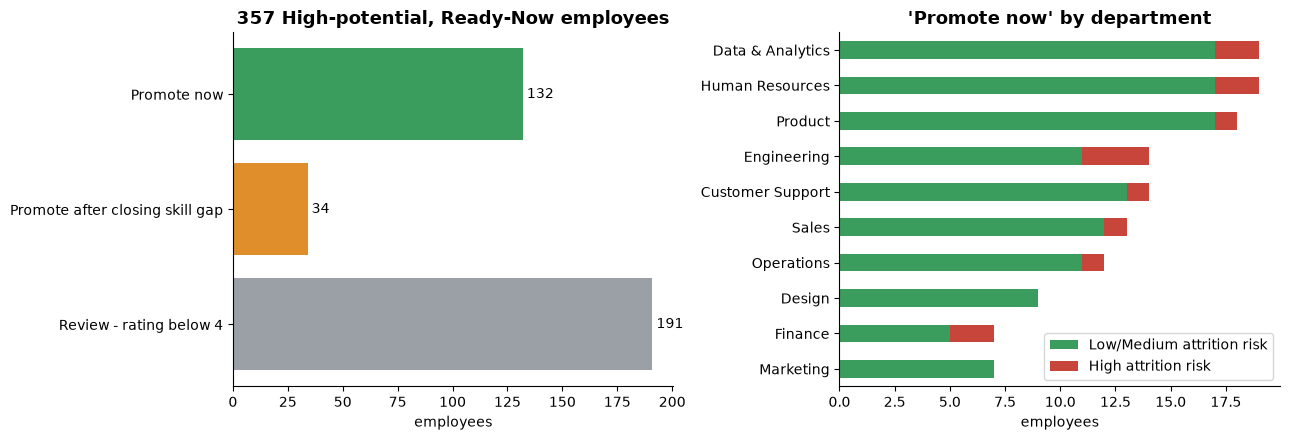

132 employees are ready to promote now; 13 of them are also at HIGH attrition risk.


In [9]:
pc = gold["gold_promotion_candidates"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
rec = pc["recommendation"].value_counts().reindex(["Promote now", "Promote after closing skill gap", "Review - rating below 4"])
a1.barh(rec.index[::-1], rec.values[::-1], color=[GREY, ORANGE, GREEN])
a1.set_title(f"{len(pc)} High-potential, Ready-Now employees"); a1.set_xlabel("employees")
for y, v in enumerate(rec.values[::-1]):
    a1.text(v, y, f" {v}", va="center")
ready = pc[pc["recommendation"] == "Promote now"]
by_dept = ready.groupby(["department", "flight_risk"]).size().unstack(fill_value=0).reindex(columns=[False, True], fill_value=0)
by_dept = by_dept.loc[by_dept.sum(axis=1).sort_values().index]
by_dept.plot.barh(stacked=True, ax=a2, color=[GREEN, RED])
a2.set_title("'Promote now' by department"); a2.set_xlabel("employees"); a2.set_ylabel("")
a2.legend(["Low/Medium attrition risk", "High attrition risk"])
plt.tight_layout(); plt.show()
print(f"{len(ready)} employees are ready to promote now; {int(ready['flight_risk'].sum())} of them are also at HIGH attrition risk.")

In [10]:
# 'Promote now' list — flight risks first within the top-rated
ready.sort_values(["flight_risk", "latest_rating"], ascending=False)[
    ["full_name", "department", "job_level", "tenure_years", "latest_rating", "performance_trend",
     "certifications_earned", "attrition_risk"]].head(15)

,full_name,department,job_level,tenure_years,latest_rating,performance_trend,certifications_earned,attrition_risk
0,Daniel Osborne,Customer Support,Manager,5.77,5,Improving,2,High
1,Paul Smith,Engineering,IC3,6.4,5,Improving,1,High
2,James Mccarthy,Human Resources,IC3,0.25,5,Improving,1,High
3,Kevin Bryant,Finance,IC2,6.19,5,Improving,0,High
47,Heather Davis,Sales,Director,2.52,4,Improving,1,High
48,Dennis Scott,Engineering,IC2,4.81,4,Stable,2,High
49,Andrea Chen,Engineering,Senior Manager,5.96,4,Improving,0,High
50,Joseph Nash,Product,Manager,7.08,4,Improving,0,High
51,Jennifer Carter,Human Resources,IC3,6.75,4,Improving,0,High
52,Jonathan Holmes,Operations,IC3,7.82,4,Improving,2,High


**So what?** 357 people are rated high-potential and ready now, but only **132 are clear "promote now" cases** (strong current rating and no critical gaps). **34** are strong performers who should close a specific skill gap first. More than half (191) carry a "ready now" label despite a latest rating below 4 — a calibration issue for the talent review panel to resolve. Promotions for the "promote now" employees who are also high attrition risk should be prioritised to avoid losing them.

## Q4. What training and development activities have been completed by each employee?

`gold_employee_learning` has **one row per employee** (including people with no learning at all): courses completed, certifications earned, modules, quiz pass rate, last activity and the list of completed courses. `gold_course_completions` has one row per employee × course completed.

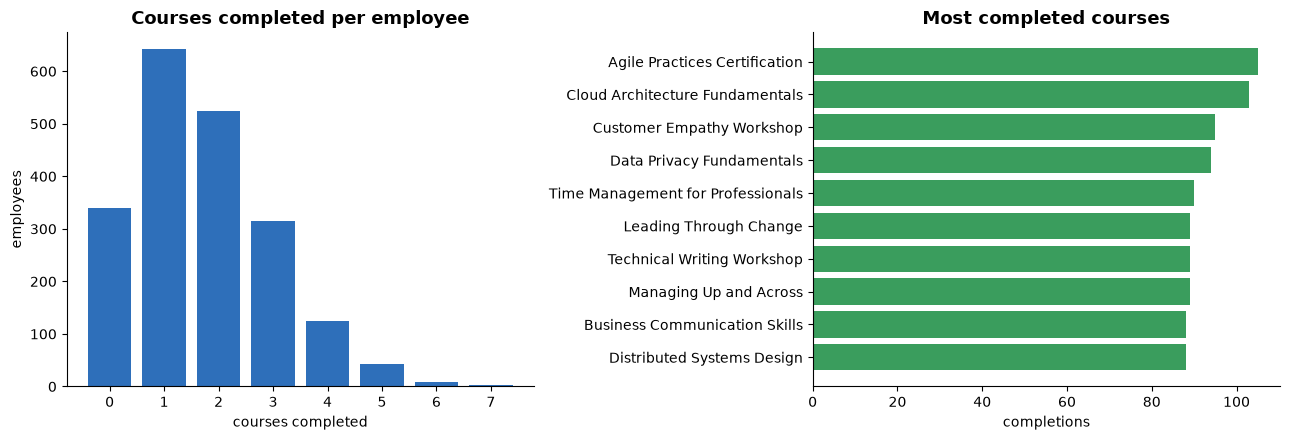

Average 1.7 courses and 0.9 certifications per employee; 339 employees (17%) have not completed any course.


,courses_completed,certifications_earned,quiz_pass_rate_pct
department,,,
Product,1.85,0.88,40.99
Finance,1.85,0.77,39.85
Sales,1.84,0.97,42.70
Data & Analytics,1.81,0.83,42.75
Engineering,1.77,0.93,40.09
Design,1.72,0.79,37.78
Marketing,1.65,0.95,41.19
Operations,1.59,0.84,43.25
Human Resources,1.58,0.88,38.41


In [11]:
el = gold["gold_employee_learning"]
cc = gold["gold_course_completions"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
dist = el["courses_completed"].value_counts().sort_index()
a1.bar(dist.index.astype(str), dist.values, color=BLUE)
a1.set_title("Courses completed per employee"); a1.set_xlabel("courses completed"); a1.set_ylabel("employees")
top = cc["course_name"].value_counts().head(10).sort_values()
a2.barh(top.index, top.values, color=GREEN)
a2.set_title("Most completed courses"); a2.set_xlabel("completions")
plt.tight_layout(); plt.show()
print(f"Average {el['courses_completed'].mean():.1f} courses and {el['certifications_earned'].mean():.1f} certifications per employee; "
      f"{(el['courses_completed'] == 0).sum()} employees ({(el['courses_completed'] == 0).mean():.0%}) have not completed any course.")
dept = el.groupby("department")[["courses_completed", "certifications_earned", "quiz_pass_rate_pct"]].mean().round(2)
dept.sort_values("courses_completed", ascending=False)

In [12]:
# Per-employee training record (first 10 shown)
el[["employee_id", "full_name", "department", "courses_completed", "certifications_earned", "modules_completed",
    "quiz_pass_rate_pct", "last_learning_date", "completed_courses_list", "certifications_list"]].head(10)

,employee_id,full_name,department,courses_completed,certifications_earned,modules_completed,quiz_pass_rate_pct,last_learning_date,completed_courses_list,certifications_list
0,1,Heather Davis,Sales,2,1,1,37.5,2026-06-23 10:59:00,Distributed Systems Design; SQL Performance Tuning,Cloud Architecture Fundamentals
1,2,Kristie Heath,Sales,2,2,5,25.0,2026-07-16 18:37:00,Effective Decision Making; Market Analysis Techniques,Business Communication Skills; Forecasting and Planning
2,3,Brandon Scott,Sales,3,1,6,42.9,2026-08-31 11:38:00,Effective Decision Making; Financial Acumen for Non-Finance Leader...,Leading Through Change
3,4,Gregory Williams,Sales,2,0,4,0.0,2026-02-25 18:05:00,Business Communication Skills; Effective Decision Making,
4,5,Linda Murray,Sales,2,1,4,50.0,2026-07-24 18:04:00,Cloud Architecture Fundamentals; Dimensional Data Modeling,Effective Decision Making
5,6,Claudia Cole,Sales,0,0,1,0.0,2026-03-04 07:31:00,,
6,7,April Harrington,Sales,1,1,3,NaN,2026-07-16 11:51:00,Market Analysis Techniques,Financial Acumen for Non-Finance Leaders
7,8,Sherry Coleman,Sales,2,4,2,25.0,2026-05-28 09:26:00,Presentation Skills Masterclass; Security Fundamentals for Engineers,Distributed Systems Design; Localization Best Practices; Risk Mana...
8,9,Kyle Brown,Sales,0,2,2,33.3,2026-07-03 13:08:00,,Forecasting and Planning; SQL Performance Tuning
9,10,Tracie Gomez,Sales,2,1,3,0.0,2026-07-28 14:16:00,Advanced Python for Data Engineers; Negotiation Tactics,Time Management for Professionals


**So what?** Every employee has some learning activity, but completion is thin: on average **1.7 courses** per person over three years, and **339 employees (17%) have never completed a course**. Completion levels are similar across departments, so this is a company-wide habit rather than one team's problem. The per-employee table is a ready-made training record for managers; linking assigned courses to the critical gaps in Q2 would make learning far more targeted.

*Data observation:* some certifications appear without a matching course-completion event — worth confirming with the learning-platform owner.

## Q5. Which employees are at risk of attrition based on performance trends?

We combine the manager's attrition flag with **observable warning signs** into a score (0–5), one point each:
1. Rating declined since the previous review
2. Rating dropped by 2+ points
3. Latest rating is low (1–2)
4. Talent review flagged attrition risk as High
5. No learning activity in the last 12 months

**Computed risk**: High = 3+ points, Medium = 2. The table lists everyone at Medium/High risk or with a declining trend. **Regretted loss** = high potential or previously rated 4+.

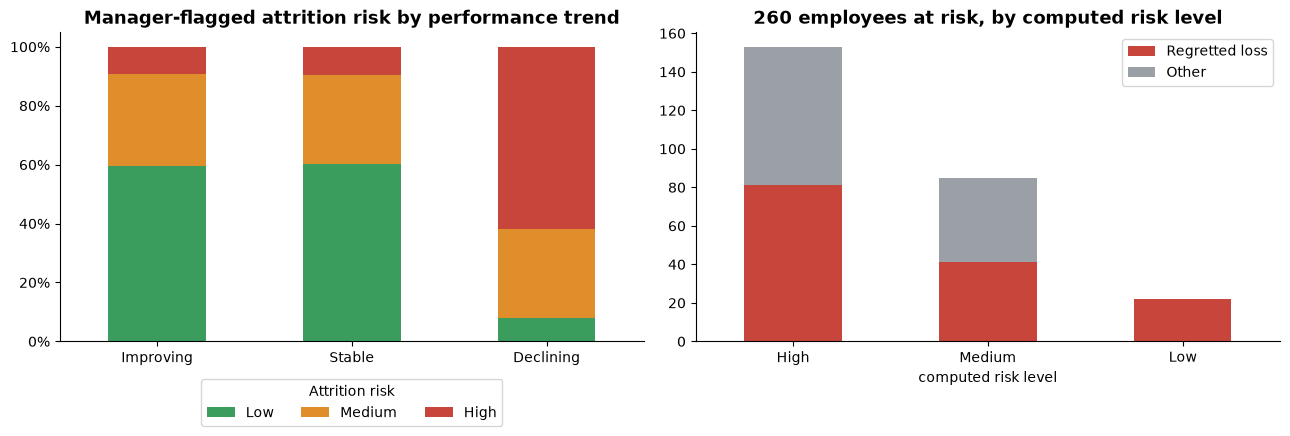

Declining performers flagged High risk: 62% vs 10% for stable performers.


In [13]:
e360 = gold["gold_employee_360"]
ar = gold["gold_attrition_risk"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
x = pd.crosstab(e360["performance_trend"], e360["attrition_risk"], normalize="index").reindex(
    index=["Improving", "Stable", "Declining"], columns=["Low", "Medium", "High"]) * 100
x.plot.bar(stacked=True, ax=a1, color=[GREEN, ORANGE, RED], rot=0)
a1.set_title("Manager-flagged attrition risk by performance trend")
a1.yaxis.set_major_formatter(mtick.PercentFormatter()); a1.set_xlabel("")
a1.legend(title="Attrition risk", ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
lvl = ar.groupby(["computed_risk_level", "regretted_loss"]).size().unstack(fill_value=0).reindex(
    index=["High", "Medium", "Low"], columns=[True, False], fill_value=0)
lvl.plot.bar(stacked=True, ax=a2, color=[RED, GREY], rot=0)
a2.set_title(f"{len(ar)} employees at risk, by computed risk level"); a2.set_xlabel("computed risk level")
a2.legend(["Regretted loss", "Other"])
plt.tight_layout(); plt.show()
print(f"Declining performers flagged High risk: {x.loc['Declining', 'High']:.0f}% vs {x.loc['Stable', 'High']:.0f}% for stable performers.")

In [14]:
# Top of the at-risk list — regretted losses first
ar[ar["regretted_loss"]].head(15)[["full_name", "department", "job_level", "previous_rating", "latest_rating",
                                     "attrition_risk", "potential_rating", "risk_score", "risk_reasons"]]

,full_name,department,job_level,previous_rating,latest_rating,attrition_risk,potential_rating,risk_score,risk_reasons
0,Anne Long,Operations,IC1,4,2,High,Medium,5,Rating declined; Rating dropped 2+ points; Low latest rating (1-2)...
3,Nicholas Gonzales,Customer Support,IC1,4,2,High,Medium,4,Rating declined; Rating dropped 2+ points; Low latest rating (1-2)...
4,Karen Rosales,Customer Support,Manager,4,2,High,High,4,Rating declined; Rating dropped 2+ points; Low latest rating (1-2)...
6,Paula Davies,Product,Manager,3,1,High,High,4,Rating declined; Rating dropped 2+ points; Low latest rating (1-2)...
7,Juan Thomas,Data & Analytics,Director,4,2,High,Medium,4,Rating declined; Rating dropped 2+ points; Low latest rating (1-2)...
8,Desiree Robertson,Data & Analytics,Director,3,1,High,High,4,Rating declined; Rating dropped 2+ points; Low latest rating (1-2)...
9,Charles Smith,Operations,IC1,3,1,High,High,4,Rating declined; Rating dropped 2+ points; Low latest rating (1-2)...
10,Kenneth Kane,Data & Analytics,IC3,4,2,High,Medium,4,Rating declined; Rating dropped 2+ points; Low latest rating (1-2)...
11,Sean Jackson,Data & Analytics,Manager,4,2,High,Medium,4,Rating declined; Rating dropped 2+ points; Low latest rating (1-2)...
12,Christopher Jenkins,Marketing,Senior Manager,4,2,High,Medium,4,Rating declined; Rating dropped 2+ points; Low latest rating (1-2)...


**So what?** A falling rating is the strongest warning sign in the data: **62% of employees whose rating declined are flagged High attrition risk, versus about 10% of everyone else**. 260 employees show a declining trend or a Medium/High computed risk; **153 are High risk**, and **144 would be regretted losses** (high potential or previously strong performers). HR should start retention conversations with the regretted-loss list above — the `risk_reasons` column explains exactly why each person is on it.

## Q6. How does employee performance correlate with team and project outcomes?

`gold_team_outcomes` has one row per team: people metrics (average rating, % high performers, rating change, skill gap) joined to project metrics (on-time rate, average outcome score). 27 of 100 teams have projects.

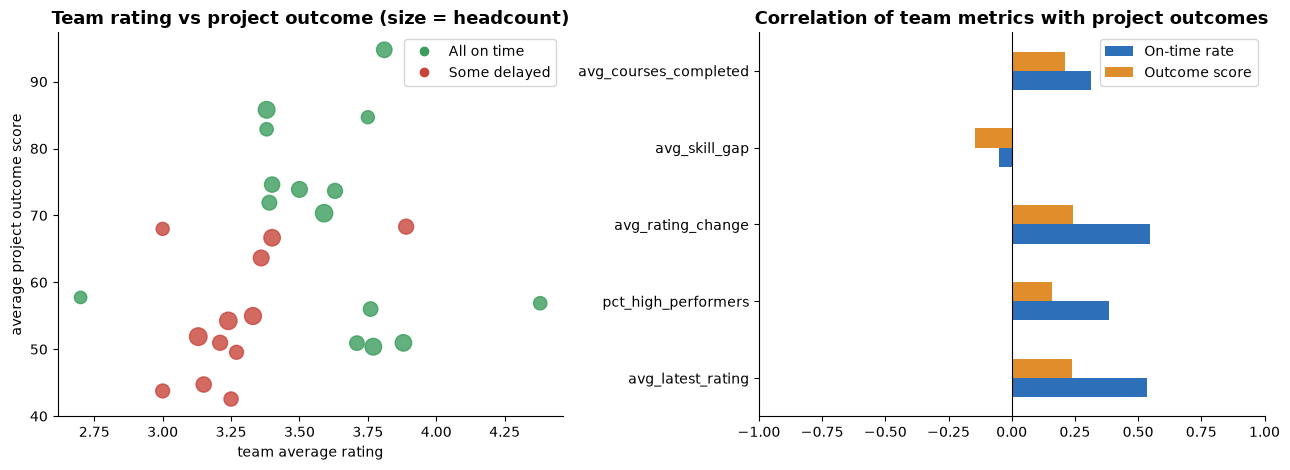

,avg_latest_rating,pct_high_performers,avg_rating_change,avg_project_outcome_score
delivery_status,,,,
All on time,3.6,56.16,0.55,69.02
Some delayed,3.27,44.71,0.35,54.94


In [15]:
to = gold["gold_team_outcomes"]
tp = to[to["projects"] > 0]
metrics = ["avg_latest_rating", "pct_high_performers", "avg_rating_change", "avg_skill_gap", "avg_courses_completed"]
corr = tp[metrics + ["on_time_rate_pct", "avg_project_outcome_score"]].astype(float).corr().loc[
    metrics, ["on_time_rate_pct", "avg_project_outcome_score"]]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
colors = tp["delivery_status"].map({"All on time": GREEN, "Some delayed": RED})
a1.scatter(tp["avg_latest_rating"], tp["avg_project_outcome_score"], c=colors, s=40 + 4 * tp["headcount"], alpha=0.8)
a1.set_xlabel("team average rating"); a1.set_ylabel("average project outcome score")
a1.set_title("Team rating vs project outcome (size = headcount)")
handles = [plt.Line2D([], [], marker="o", ls="", color=c) for c in (GREEN, RED)]
a1.legend(handles, ["All on time", "Some delayed"])
corr.rename(columns={"on_time_rate_pct": "On-time rate", "avg_project_outcome_score": "Outcome score"}).plot.barh(
    ax=a2, color=[BLUE, ORANGE])
a2.axvline(0, color="black", lw=0.8); a2.set_xlim(-1, 1)
a2.set_title("Correlation of team metrics with project outcomes")
plt.tight_layout(); plt.show()
tp.groupby("delivery_status")[["avg_latest_rating", "pct_high_performers", "avg_rating_change",
                                "avg_project_outcome_score"]].mean().round(2)

**So what?** Team performance and project delivery move together: the team's **average rating correlates +0.54 with on-time delivery**, and so does the team's rating improvement. Teams that delivered **every** project on time average 3.6 vs 3.3 and have ~56% vs ~45% high performers. Team skill gaps and course completions show almost no relationship with delivery. Caveat: only 27 teams / 33 projects, so this is a strong signal to investigate, not proof of cause.

## Q7. What is the distribution of skills across the organization?

`gold_skill_distribution` has one row per department × competency with the full proficiency histogram (levels 1–5), averages, % meeting requirement and % at expert level (4–5).

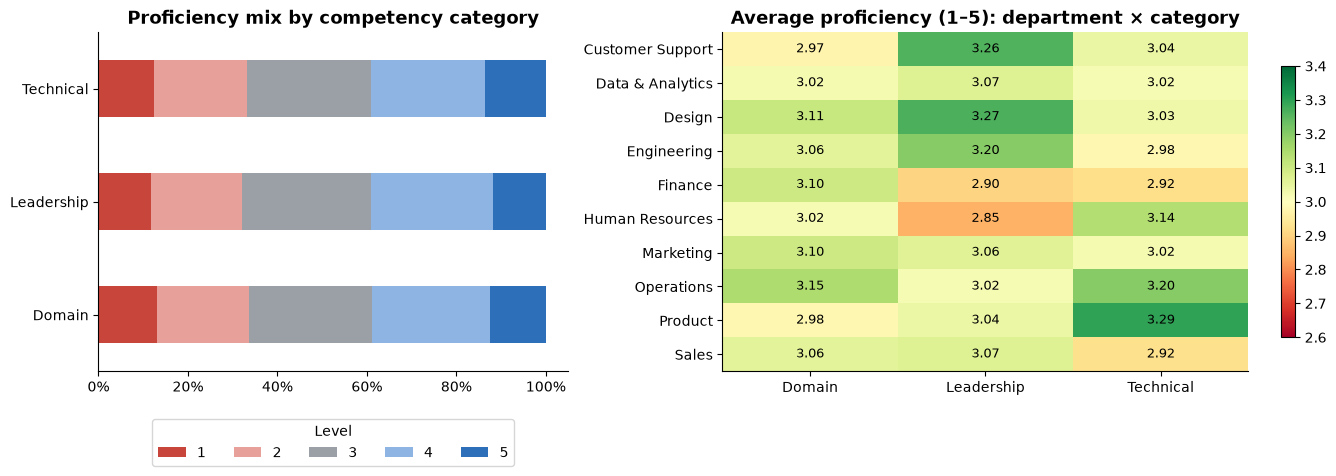

In [16]:
sd = gold["gold_skill_distribution"]
levels = [f"level_{i}_count" for i in range(1, 6)]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.4]})
cat = sd.groupby("category")[levels].sum()
(cat.div(cat.sum(axis=1), axis=0) * 100).plot.barh(stacked=True, ax=a1, color=[RED, "#E8A09A", GREY, "#8DB4E2", BLUE])
a1.set_title("Proficiency mix by competency category"); a1.xaxis.set_major_formatter(mtick.PercentFormatter())
a1.legend([str(i) for i in range(1, 6)], title="Level", ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.3)); a1.set_ylabel("")

pivot = (sd.assign(w=sd["avg_proficiency"] * sd["assessments"]).groupby(["department", "category"])[["w", "assessments"]].sum())
heat = (pivot["w"] / pivot["assessments"]).astype(float).unstack()
im = a2.imshow(heat.values, cmap="RdYlGn", vmin=2.6, vmax=3.4, aspect="auto")
a2.set_xticks(range(len(heat.columns)), heat.columns); a2.set_yticks(range(len(heat.index)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        a2.text(j, i, f"{heat.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
a2.set_title("Average proficiency (1–5): department × category")
plt.colorbar(im, ax=a2, shrink=0.8)
plt.tight_layout(); plt.show()

In [17]:
# Company-wide view per competency: strongest and weakest skills
comp = sd.groupby(["competency_name", "category"])[levels + ["assessments", "meets_requirement", "critical_gaps"]].sum()
comp["pct_meeting_requirement"] = (100 * comp["meets_requirement"] / comp["assessments"]).round(1)
comp["pct_expert_4_5"] = (100 * (comp["level_4_count"] + comp["level_5_count"]) / comp["assessments"]).round(1)
comp = comp.sort_values("pct_meeting_requirement")
print("Weakest 5 (lowest % meeting requirement):")
display(comp.head(5)[["assessments", "pct_meeting_requirement", "pct_expert_4_5", "critical_gaps"]])
print("Strongest 5:")
display(comp.tail(5)[["assessments", "pct_meeting_requirement", "pct_expert_4_5", "critical_gaps"]])

Weakest 5 (lowest % meeting requirement):


,,assessments,pct_meeting_requirement,pct_expert_4_5,critical_gaps
competency_name,category,,,,
Stakeholder Management,Domain,92,65.2,23.9,14
Customer Empathy,Domain,88,68.2,37.5,8
Presentation Skills,Domain,105,69.5,42.9,12
Incident Response,Technical,105,69.5,40.0,12
Negotiation,Domain,103,69.9,27.2,12


Strongest 5:


,,assessments,pct_meeting_requirement,pct_expert_4_5,critical_gaps
competency_name,category,,,,
Localization,Domain,109,80.7,53.2,6
Onboarding & Enablement,Domain,126,81.0,38.9,8
Decision Making,Leadership,109,81.7,37.6,9
Data Privacy,Domain,100,82.0,39.0,5
Vendor Management,Domain,101,82.2,35.6,4


**So what?** Skills are spread fairly evenly: in every category roughly 4 in 10 assessments are at expert level (4–5) and about 1 in 4 are at the bottom levels (1–2), with no department dramatically ahead or behind. The one clear hot-spot is **Leadership skills in Human Resources and Finance**, which have the lowest average proficiency on the heatmap. The weak spots are specific competencies rather than whole categories — **Stakeholder Management** has the lowest share of people meeting requirement (~65%), while **Localization, Cloud Architecture and Financial Acumen** are the organisation's strongest skills. Note: each employee has only two assessments, so department × competency cells are small; read individual cells as indicative.

## Summary and recommendations

| Question | Headline | Suggested action |
|---|---|---|
| Q1 | Ratings rose overall (3.02 → 3.41); 230 employees (12%) declined | Use review history in conversations with decliners; check rating-scale consistency |
| Q2 | 317 employees have critical gaps; over half in key competencies | Build development plans from the priority list |
| Q3 | 132 clear "promote now"; 191 "ready now" despite rating < 4 | Act on the 132; recalibrate readiness labels |
| Q4 | 1.7 courses per person; 17% never completed a course | Assign courses against Q2 gaps; track completion |
| Q5 | Declining rating ⇒ 62% high attrition risk; 144 regretted-loss risks | Start retention conversations with the regretted-loss list |
| Q6 | Team rating correlates +0.54 with on-time delivery | Study practices of strong, on-time teams (small sample) |
| Q7 | Even skill spread; Stakeholder Management weakest; Leadership weak in HR & Finance | Targeted programme for the weakest competencies |

### Assumptions and limitations
* **Latest rating** = most recent review period (2025-H1); trends compare it with 2024-H2.
* Thresholds (critical gap ≥ 2, key competency required ≥ 4, high performer ≥ 4, learning inactivity 12 months) live in `pipeline/gold.py → RULES` and can be changed in one place.
* The talent review covers one cycle (2025-H1), so potential, readiness and attrition risk are a point-in-time view.
* The computed attrition score is a transparent rule-based signal, not a trained prediction model.
* Correlation is not causation — Q6 identifies relationships to investigate, not proven effects.
* All names in this dataset are synthetic.